<a href="https://colab.research.google.com/github/MinAmorim/Mineracao-de-Dados/blob/main/arvore_acidentes_prf.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Árvore de decisão: gravidade de acidentes nas rodovias federais

**Mineração de Dados · UFC · Departamento de Computação**

Classificação da gravidade de acidentes com `DecisionTreeClassifier`, em quatro passos:

1. Carregar e dividir os dados
2. Treinar e avaliar uma árvore
3. Visualizar a árvore
4. Evitar overfitting (parada antecipada, validação cruzada e poda)

**Dataset:** acidentes registrados pela Polícia Rodoviária Federal em 2026 (janeiro a agosto), arquivo "Agrupados por ocorrência" do [portal de dados abertos da PRF](https://www.gov.br/prf/pt-br/acesso-a-informacao/dados-abertos/dados-abertos-da-prf). Cada linha é um acidente.

In [ ]:
import os
import zipfile
import gdown

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score

semente = 42

## 1. Carregar e dividir os dados

### 1.1 Download

O arquivo é baixado direto do link oficial da PRF (um `.zip` no Google Drive). Como a PRF atualiza os dados de 2026 ao longo do ano, a análise fica restrita aos acidentes até 31/08/2026, para os resultados não mudarem a cada atualização.

In [ ]:
arquivo = "datatran2026.zip"

if not os.path.exists(arquivo):
    gdown.download(id="1A3IirNm0AzRaSosA1IS94DOVmvKsn0Ol", output=arquivo)

with zipfile.ZipFile(arquivo) as z:
    nome = [n for n in z.namelist() if n.endswith(".csv")][0]
    dados = pd.read_csv(z.open(nome), sep=";", decimal=",", encoding="latin-1")

dados = dados[dados["data_inversa"] <= "2026-08-31"]
print(dados.shape)
dados.head()

(48712, 30)


,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,742921.0,2026-01-01,quinta-feira,04:04:00,TO,153,155.0,ARAGUAINA,Objeto estático sobre o leito carroçável,Tombamento,...,0,1,3,0,5,-7.291548,-48.286252,SPRF-TO,DEL02-TO,UOP01-DEL02-TO
1,742942.0,2026-01-01,quinta-feira,06:40:00,MG,262,146.1,RIO CASCA,Condutor Dormindo,Colisão frontal,...,4,1,1,4,3,-20.024073,-42.742229,SPRF-MG,DEL03-MG,UOP03-DEL03-MG
2,742943.0,2026-01-01,quinta-feira,06:58:00,SC,101,193.0,BIGUACU,Reação tardia ou ineficiente do condutor,Colisão lateral mesmo sentido,...,0,1,2,1,4,-27.489352,-48.655658,SPRF-SC,DEL01-SC,UOP01-DEL01-SC
3,742947.0,2026-01-01,quinta-feira,07:05:00,DF,60,23.0,BRASILIA,Reação tardia ou ineficiente do condutor,Colisão traseira,...,0,1,1,1,3,-15.988927,-48.226300,SPRF-DF,DEL03-DF,UOP01-DEL03-DF
4,742960.0,2026-01-01,quinta-feira,06:17:00,MT,163,1044.0,MATUPA,Transitar na contramão,Colisão frontal,...,1,1,3,1,5,-10.143306,-54.930756,SPRF-MT,DEL06-MT,UOP03-DEL06-MT


### 1.2 Escolha do rótulo

A coluna `classificacao_acidente` já é categórica e serve diretamente como rótulo, com três classes: **Sem Vítimas**, **Com Vítimas Feridas** e **Com Vítimas Fatais**.

In [ ]:
dados = dados.dropna(subset=["classificacao_acidente"])

contagem = dados["classificacao_acidente"].value_counts()
print(pd.DataFrame({"acidentes": contagem, "proporção": (contagem / len(dados)).round(3)}))

                        acidentes  proporção
classificacao_acidente                      
Com Vítimas Feridas         37665      0.773
Sem Vítimas                  7556      0.155
Com Vítimas Fatais           3490      0.072


As classes são bem desbalanceadas: quase 8 em cada 10 acidentes têm feridos, e os fatais são cerca de 7%. Isso exige dois cuidados:

- **Métrica:** com esse desbalanceamento, a acurácia engana. Um modelo que sempre responde "Com Vítimas Feridas" já passa de 77%. Por isso, a escolha dos modelos usa o **F1 macro**, que dá o mesmo peso às três classes. A acurácia continua sendo mostrada.
- **Peso das classes:** todas as árvores usam `class_weight="balanced"`, que aumenta o peso das classes raras no treino. Sem isso, a árvore praticamente ignora os acidentes fatais.

### 1.3 Pré-processamento

Antes de treinar, os dados passam por algumas etapas:

**Colunas que vazam o rótulo.** `mortos`, `feridos_leves`, `feridos_graves`, `feridos`, `ilesos` e `ignorados` contam as vítimas, e a classificação é calculada a partir delas. Se ficassem, a árvore só aprenderia "se mortos > 0, então fatal". Elas são removidas.

**Colunas sem uso.** `id`, `municipio` (centenas de valores), `latitude`, `longitude`, `km`, `regional`, `delegacia` e `uop`.

**Transformações:**
- de `horario` fica a hora (0 a 23) e de `data_inversa`, o mês;
- `br` é um código, não uma quantidade, então entra como categoria;
- `tracado_via` junta vários valores no mesmo campo (ex.: `"Aclive;Reta"`), então vira uma coluna binária para cada traçado;
- as demais colunas de texto viram colunas binárias (one-hot), porque a árvore do scikit-learn não aceita texto.

Árvores de decisão não precisam de normalização dos atributos, então essa etapa não é feita.

In [ ]:
vazamento = ["mortos", "feridos_leves", "feridos_graves", "feridos", "ilesos", "ignorados"]
sem_uso = ["id", "municipio", "latitude", "longitude", "km", "regional", "delegacia", "uop"]
dados = dados.drop(columns=vazamento + sem_uso)

dados["hora"] = pd.to_datetime(dados["horario"], format="%H:%M:%S").dt.hour
dados["mes"] = pd.to_datetime(dados["data_inversa"]).dt.month
dados["br"] = dados["br"].astype(str)

tracado = dados["tracado_via"].str.get_dummies(sep=";").add_prefix("tracado_")
dados = pd.concat([dados.drop(columns=["horario", "data_inversa", "tracado_via"]), tracado], axis=1)

dados = dados.dropna()

y = dados["classificacao_acidente"]
x = dados.drop(columns=["classificacao_acidente"])

categoricas = x.select_dtypes(exclude="number").columns
x = pd.get_dummies(x, columns=categoricas, dtype=int)

classes = sorted(y.unique())
print("atributos depois do one-hot:", x.shape[1])

atributos depois do one-hot: 269


### 1.4 Divisão treino / teste

70% treino e 30% teste, com divisão estratificada para manter a proporção das classes nos dois conjuntos. O teste só é usado no final.

In [ ]:
x_treino, x_teste, y_treino, y_teste = train_test_split(
    x, y, test_size=0.30, stratify=y, random_state=semente
)

print("treino:", x_treino.shape, "| teste:", x_teste.shape)

treino: (34097, 269) | teste: (14614, 269)


## 2. Treinar e avaliar

Árvore com os parâmetros padrão (sem limite de crescimento), só com o peso das classes balanceado.

In [ ]:
arvore = DecisionTreeClassifier(class_weight="balanced", random_state=semente)
arvore.fit(x_treino, y_treino)

print(f"profundidade: {arvore.get_depth()} | folhas: {arvore.get_n_leaves()}")
print(f"acurácia treino: {arvore.score(x_treino, y_treino):.3f}")
print(f"acurácia teste : {arvore.score(x_teste, y_teste):.3f}")
print(f"F1 macro treino: {f1_score(y_treino, arvore.predict(x_treino), average='macro'):.3f}")
print(f"F1 macro teste : {f1_score(y_teste, arvore.predict(x_teste), average='macro'):.3f}")

profundidade: 69 | folhas: 9652
acurácia treino: 1.000
acurácia teste : 0.694
F1 macro treino: 1.000
F1 macro teste : 0.467


> **Sinal de overfitting:** o treino fica perto de 1,000 e o teste bem abaixo. Com dezenas de milhares de acidentes e centenas de atributos, a árvore cresce até decorar o treino. Isso é tratado na Seção 4.

Métodos úteis de uma árvore treinada:

In [ ]:
amostra = x_teste.iloc[[0]]

print("classe real   :", y_teste.iloc[0])
print("predict       :", arvore.predict(amostra)[0])
print("predict_proba :", dict(zip(arvore.classes_, arvore.predict_proba(amostra)[0].round(3).tolist())))
print("apply         : folha nº", arvore.apply(amostra)[0])

top5 = pd.Series(arvore.feature_importances_, index=x.columns).nlargest(5)
print("\nfeature_importances_ (top 5):")
print(top5.round(3).to_string())

classe real   : Com Vítimas Feridas
predict       : Com Vítimas Fatais
predict_proba : {'Com Vítimas Fatais': 1.0, 'Com Vítimas Feridas': 0.0, 'Sem Vítimas': 0.0}
apply         : folha nº 16377

feature_importances_ (top 5):
hora                                       0.076
tipo_acidente_Colisão frontal              0.060
mes                                        0.057
tipo_acidente_Incêndio                     0.048
tipo_acidente_Atropelamento de Pedestre    0.043


## 3. Visualizar a árvore

A árvore sem restrições tem milhares de folhas, então o desenho mostra só os primeiros níveis.

Nos atributos do one-hot, o teste `tipo_acidente_Colisão frontal <= 0.5` quer dizer "não é colisão frontal" (ramo esquerdo) ou "é colisão frontal" (ramo direito).

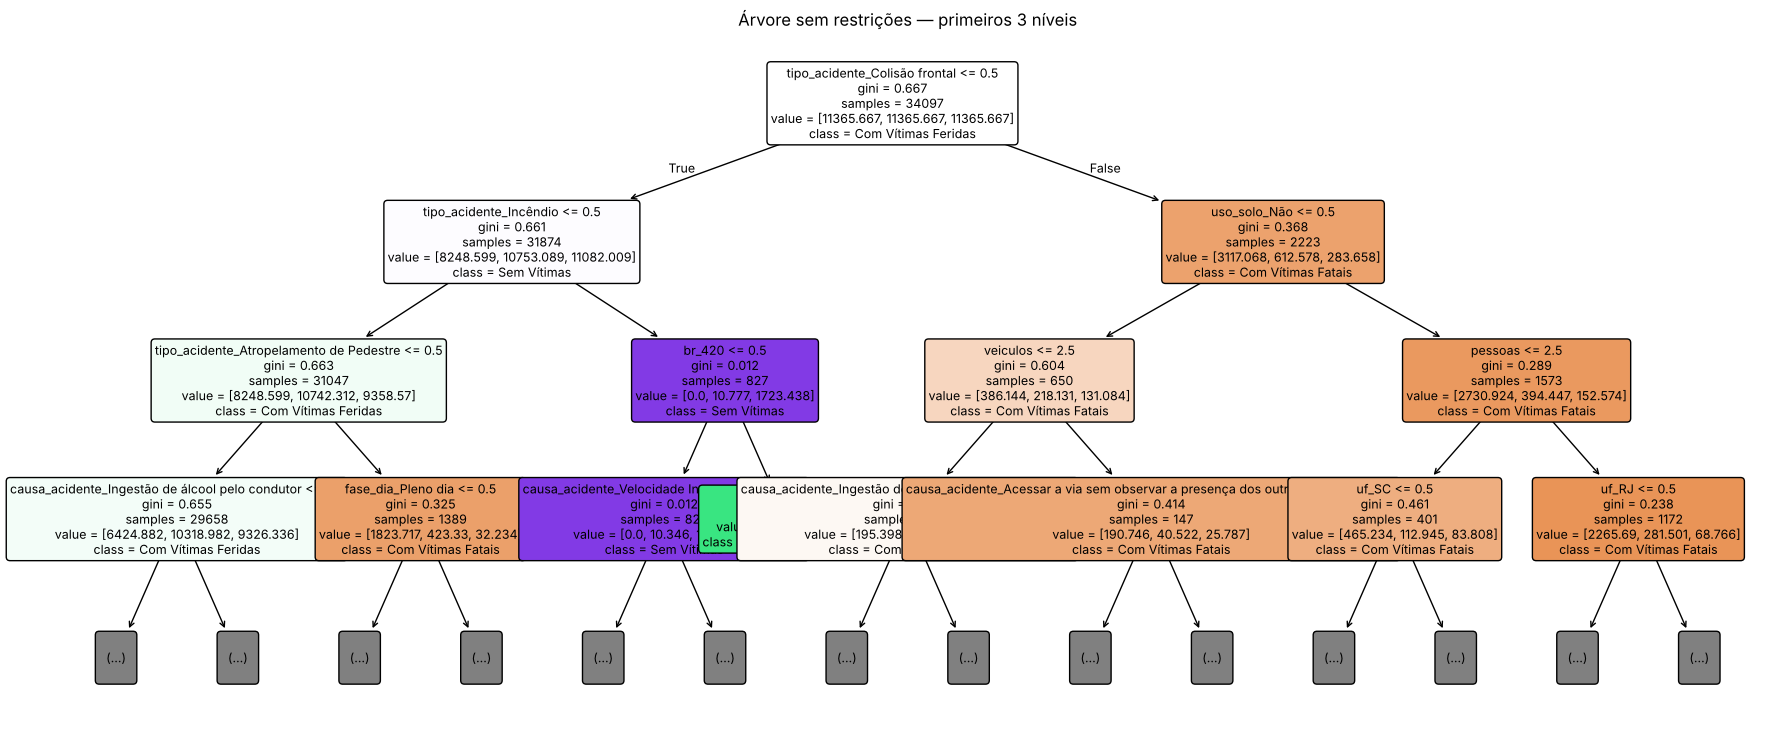

In [ ]:
fig, ax = plt.subplots(figsize=(22, 9))
plot_tree(
    arvore,
    max_depth=3,
    feature_names=x.columns,
    class_names=arvore.classes_,
    filled=True,
    rounded=True,
    fontsize=9,
    ax=ax,
)
ax.set_title("Árvore sem restrições — primeiros 3 níveis")
plt.show()

In [ ]:
print(export_text(arvore, feature_names=list(x.columns), max_depth=3))

|--- tipo_acidente_Colisão frontal <= 0.50
|   |--- tipo_acidente_Incêndio <= 0.50
|   |   |--- tipo_acidente_Atropelamento de Pedestre <= 0.50
|   |   |   |--- causa_acidente_Ingestão de álcool pelo condutor <= 0.50
|   |   |   |   |--- truncated branch of depth 62
|   |   |   |--- causa_acidente_Ingestão de álcool pelo condutor >  0.50
|   |   |   |   |--- truncated branch of depth 52
|   |   |--- tipo_acidente_Atropelamento de Pedestre >  0.50
|   |   |   |--- fase_dia_Pleno dia <= 0.50
|   |   |   |   |--- truncated branch of depth 64
|   |   |   |--- fase_dia_Pleno dia >  0.50
|   |   |   |   |--- truncated branch of depth 51
|   |--- tipo_acidente_Incêndio >  0.50
|   |   |--- br_420 <= 0.50
|   |   |   |--- causa_acidente_Velocidade Incompatível <= 0.50
|   |   |   |   |--- truncated branch of depth 20
|   |   |   |--- causa_acidente_Velocidade Incompatível >  0.50
|   |   |   |   |--- class: Com Vítimas Feridas
|   |   |--- br_420 >  0.50
|   |   |   |--- class: Com Vítimas Fer

## 4. Evitar overfitting

### 4.1 Diagnóstico: treino × validação cruzada

Variando `max_depth` e comparando o F1 macro no treino com o F1 macro em validação cruzada (5 folds, só no treino).

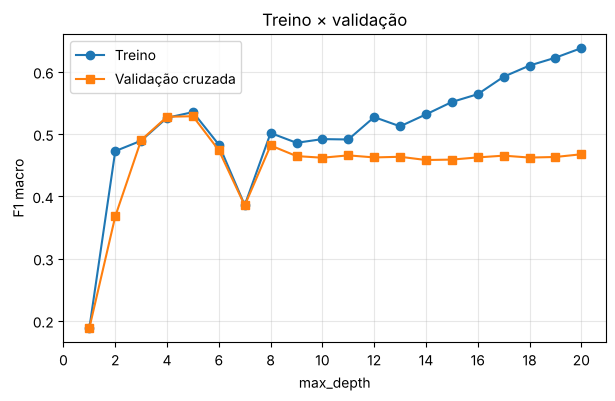

melhor profundidade na validação: 5


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=semente)

profundidades = range(1, 21)
f1_treino, f1_cv = [], []

for d in profundidades:
    m = DecisionTreeClassifier(max_depth=d, class_weight="balanced", random_state=semente)
    f1_cv.append(cross_val_score(m, x_treino, y_treino, cv=cv, scoring="f1_macro", n_jobs=-1).mean())
    m.fit(x_treino, y_treino)
    f1_treino.append(f1_score(y_treino, m.predict(x_treino), average="macro"))

plt.figure(figsize=(7, 4))
plt.plot(profundidades, f1_treino, "o-", label="Treino")
plt.plot(profundidades, f1_cv, "s-", label="Validação cruzada")
plt.xlabel("max_depth"); plt.ylabel("F1 macro"); plt.title("Treino × validação")
plt.xticks(range(0, 21, 2))
plt.legend(); plt.grid(alpha=0.3); plt.show()

print("melhor profundidade na validação:", profundidades[int(np.argmax(f1_cv))])

### 4.2 Parada antecipada (pré-poda)

Os hiperparâmetros `max_depth` e `min_samples_leaf` são escolhidos com `GridSearchCV`, usando só o treino.

Como `min_samples_leaf` é um número absoluto de amostras, os valores testados precisam acompanhar o tamanho do treino. Com mais de 34 mil acidentes, 20 amostras por folha seria só 0,06% do treino e quase não limitaria a árvore. Por isso a grade vai até 200 (cerca de 0,6%).

In [ ]:
grade = {
    "max_depth": [3, 4, 5, 6, 8, 10, None],
    "min_samples_leaf": [1, 10, 50, 100, 200],
}

busca = GridSearchCV(
    DecisionTreeClassifier(class_weight="balanced", random_state=semente),
    grade,
    cv=cv,
    scoring="f1_macro",
    n_jobs=-1,
)
busca.fit(x_treino, y_treino)

arvore_pre = busca.best_estimator_
print("melhores hiperparâmetros:", busca.best_params_)
print(f"F1 macro CV: {busca.best_score_:.3f}")

melhores hiperparâmetros: {'max_depth': 5, 'min_samples_leaf': 1}
F1 macro CV: 0.529


### 4.3 Poda por custo-complexidade (pós-poda)

A árvore completa tem milhares de folhas, então o caminho de poda gera milhares de valores de `ccp_alpha`. Testar todos com validação cruzada levaria muito tempo. Por isso são testados 30 valores em escala logarítmica, do menor ao maior alpha do caminho.

In [ ]:
caminho = DecisionTreeClassifier(class_weight="balanced", random_state=semente).cost_complexity_pruning_path(x_treino, y_treino)
todos = caminho.ccp_alphas[:-1]

alphas = np.geomspace(1e-5, todos[-1], 30)

scores = [
    cross_val_score(DecisionTreeClassifier(class_weight="balanced", random_state=semente, ccp_alpha=a),
                    x_treino, y_treino, cv=cv, scoring="f1_macro", n_jobs=-1).mean()
    for a in alphas
]

melhor_alpha = alphas[int(np.argmax(scores))]
arvore_pos = DecisionTreeClassifier(class_weight="balanced", random_state=semente, ccp_alpha=melhor_alpha).fit(x_treino, y_treino)
print(f"melhor ccp_alpha: {melhor_alpha:.6f} | F1 macro CV: {max(scores):.3f}")

melhor ccp_alpha: 0.003440 | F1 macro CV: 0.531


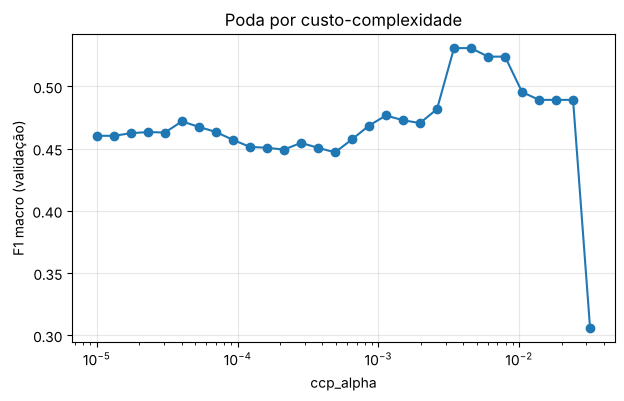

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(alphas, scores, "o-")
plt.xscale("log")
plt.xlabel("ccp_alpha"); plt.ylabel("F1 macro (validação)"); plt.title("Poda por custo-complexidade")
plt.grid(alpha=0.3); plt.show()

### 4.4 Comparação final no conjunto de teste

Só agora o teste é usado, uma única vez.

In [ ]:
modelos = {
    "Sem restrições": arvore,
    "Pré-poda (GridSearch)": arvore_pre,
    "Pós-poda (ccp_alpha)": arvore_pos,
}

pd.DataFrame([
    {"modelo": nome,
     "folhas": m.get_n_leaves(),
     "profundidade": m.get_depth(),
     "acurácia treino": round(m.score(x_treino, y_treino), 3),
     "acurácia teste": round(m.score(x_teste, y_teste), 3),
     "F1 macro treino": round(f1_score(y_treino, m.predict(x_treino), average="macro"), 3),
     "F1 macro teste": round(f1_score(y_teste, m.predict(x_teste), average="macro"), 3)}
    for nome, m in modelos.items()
]).set_index("modelo")

,folhas,profundidade,acurácia treino,acurácia teste,F1 macro treino,F1 macro teste
modelo,,,,,,
Sem restrições,9684,69,1.000,0.696,1.000,0.470
Pré-poda (GridSearch),28,5,0.762,0.766,0.535,0.542
Pós-poda (ccp_alpha),9,8,0.704,0.706,0.531,0.539


As duas árvores regularizadas são **muito menores** que a árvore sem restrições (9.684 folhas) e generalizam bem melhor: o F1 macro no teste sobe de 0,470 para cerca de 0,54, e o treino deixa de ser 1,000, ficando quase igual ao teste.

A pré-poda e a pós-poda têm F1 macro de teste praticamente igual (0,542 × 0,539), mas a pós-poda usa **9 folhas** em vez de 28. Seguindo a regra de preferir a árvore menor entre modelos de desempenho parecido, o modelo final é a **árvore pós-podada**.

A pré-poda tem acurácia maior (0,766 × 0,706) porque acerta mais a classe majoritária. A pós-poda troca um pouco dessa acurácia por um recall maior nas classes minoritárias, que é justamente o que o F1 macro valoriza.

### 4.5 O modelo final

Com 9 folhas, a árvore pode ser desenhada inteira.

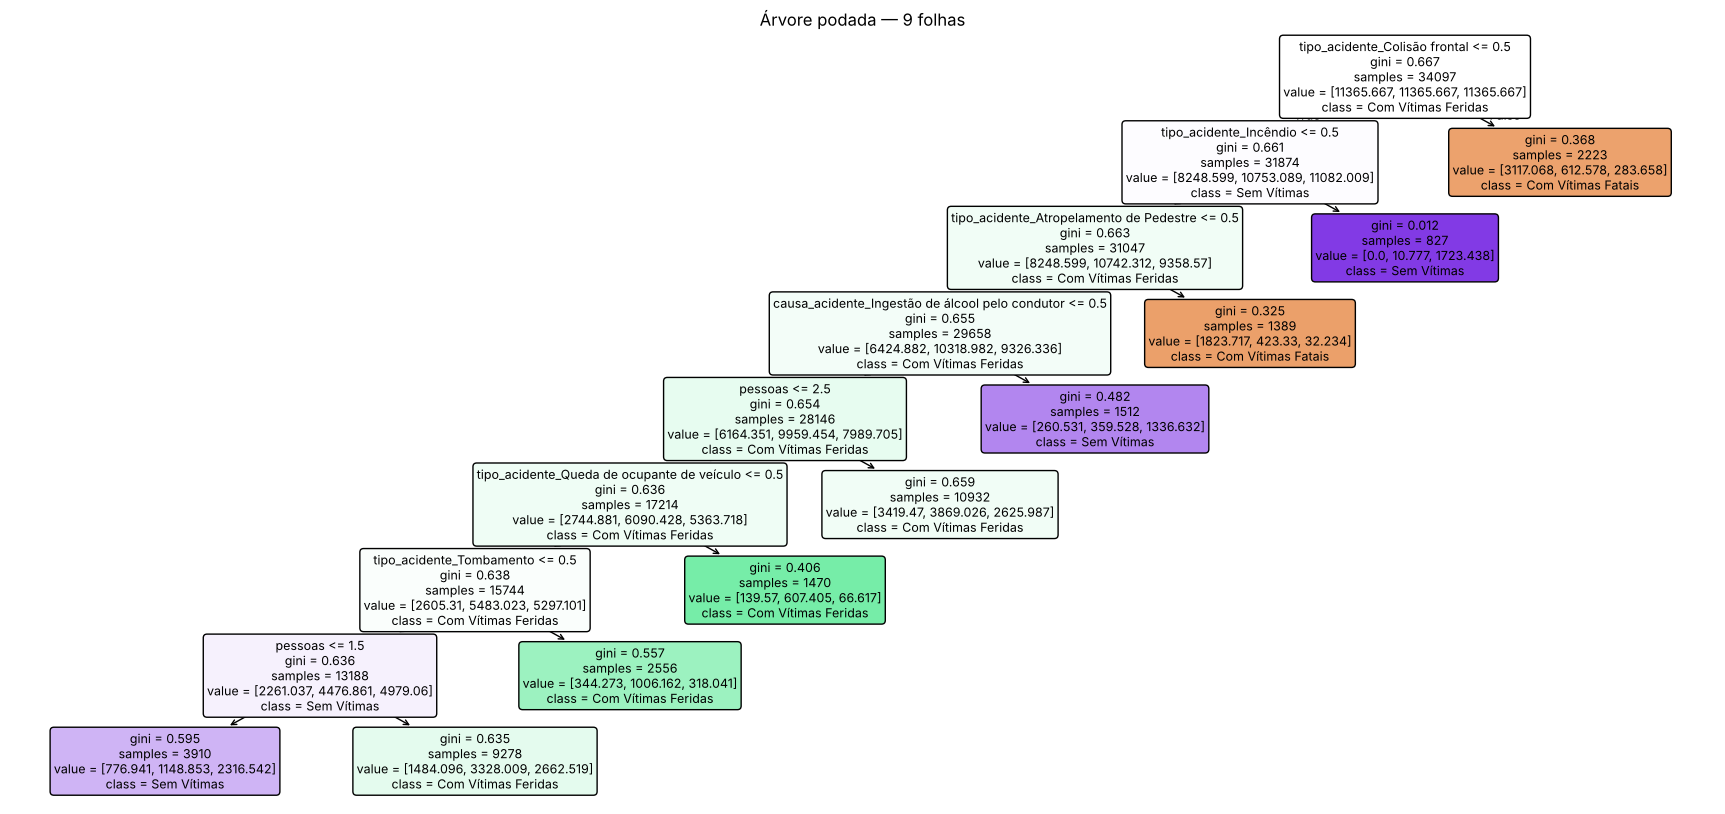

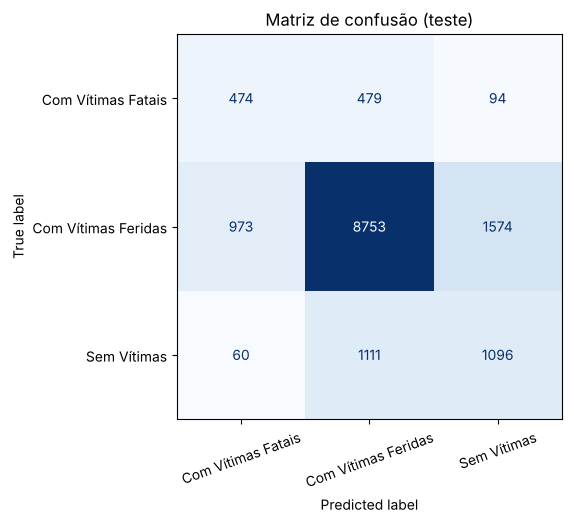

                     precision    recall  f1-score   support

 Com Vítimas Fatais      0.315     0.453     0.371      1047
Com Vítimas Feridas      0.846     0.775     0.809     11300
        Sem Vítimas      0.397     0.483     0.436      2267

           accuracy                          0.706     14614
          macro avg      0.519     0.570     0.539     14614
       weighted avg      0.738     0.706     0.720     14614



In [ ]:
final = arvore_pos

fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(final, feature_names=x.columns, class_names=final.classes_,
          filled=True, rounded=True, fontsize=9, ax=ax)
ax.set_title(f"Árvore podada — {final.get_n_leaves()} folhas")
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_estimator(final, x_teste, y_teste, cmap="Blues",
                                      colorbar=False, xticks_rotation=20, ax=ax)
ax.set_title("Matriz de confusão (teste)")
plt.show()

print(classification_report(y_teste, final.predict(x_teste), digits=3))

In [ ]:
print(export_text(final, feature_names=list(x.columns)))

|--- tipo_acidente_Colisão frontal <= 0.50
|   |--- tipo_acidente_Incêndio <= 0.50
|   |   |--- tipo_acidente_Atropelamento de Pedestre <= 0.50
|   |   |   |--- causa_acidente_Ingestão de álcool pelo condutor <= 0.50
|   |   |   |   |--- pessoas <= 2.50
|   |   |   |   |   |--- tipo_acidente_Queda de ocupante de veículo <= 0.50
|   |   |   |   |   |   |--- tipo_acidente_Tombamento <= 0.50
|   |   |   |   |   |   |   |--- pessoas <= 1.50
|   |   |   |   |   |   |   |   |--- class: Sem Vítimas
|   |   |   |   |   |   |   |--- pessoas >  1.50
|   |   |   |   |   |   |   |   |--- class: Com Vítimas Feridas
|   |   |   |   |   |   |--- tipo_acidente_Tombamento >  0.50
|   |   |   |   |   |   |   |--- class: Com Vítimas Feridas
|   |   |   |   |   |--- tipo_acidente_Queda de ocupante de veículo >  0.50
|   |   |   |   |   |   |--- class: Com Vítimas Feridas
|   |   |   |   |--- pessoas >  2.50
|   |   |   |   |   |--- class: Com Vítimas Feridas
|   |   |   |--- causa_acidente_Ingestão de álc

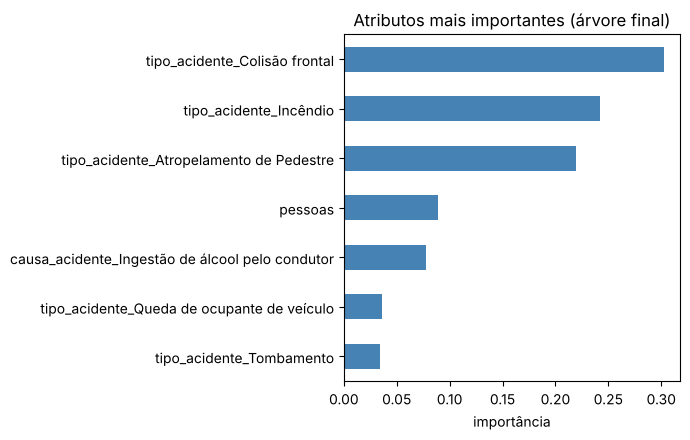

In [ ]:
importancia = pd.Series(final.feature_importances_, index=x.columns)
importancia = importancia[importancia > 0].nlargest(10)

plt.figure(figsize=(7, 4.5))
importancia.sort_values().plot.barh(color="steelblue")
plt.xlabel("importância"); plt.title("Atributos mais importantes (árvore final)")
plt.tight_layout(); plt.show()

## Resumo

- A árvore sem restrições decorou o treino: 9.684 folhas, profundidade 69, F1 macro de 1,000 no treino e 0,470 no teste.
- Com regularização, escolhida por validação cruzada só no treino, a árvore fica com 9 folhas e F1 macro de 0,539 no teste, sem diferença entre treino e teste.
- A árvore final é fácil de ler: **colisão frontal** e **atropelamento** levam a "Com Vítimas Fatais"; **incêndio** e acidentes com **ingestão de álcool** (fora esses tipos) levam a "Sem Vítimas"; o resto, na maioria, vai para "Com Vítimas Feridas", com um ajuste pelo número de pessoas envolvidas.
- O modelo encontra cerca de 45% dos acidentes fatais e 48% dos sem vítimas, mas com precisão baixa nessas classes (0,32 e 0,40). As condições registradas pela PRF explicam só parte da gravidade: velocidade real, uso de cinto e tipo de veículo, que pesam muito, não estão neste arquivo.
- Como as classes são desbalanceadas, a acurácia sozinha seria enganosa. O F1 macro com `class_weight="balanced"` foi necessário para o modelo não ignorar os acidentes fatais.